## Problem statement 

How effectively we can predict elevated obesity prevalence risk of childhood (obese or not) of 3-23 months and 2-4 years of age children in the WIC program from US states. By using the Logistic Regression and CatBoost models, what impact does feature engineering have and how they perform in terms of classification accuracy, precision, recall, F1 score, and ROC AUC?



## 1.Introduction and Dataset Overview



##### DatasetName: Nutrition, Physical Activity, and Obesity - Women, Infant, and Child
##### Source: https://catalog.data.gov/dataset/nutrition-physical-activity-and-obesity-women-infant-and-child
##### Purpose: Predict prevalence rates of health metrics (e.g., obesity, physical activity) across US states.
##### Problem Type: Classification (Predicting whether obesity prevalence is elevated (>15%) or not)
##### Target Variable: Elevated_Obesity Derived from Data_Value (1 if Data_Value > 15%, else 0).
##### Key Features:
##### *YearStart
##### *Sample_Size
##### *LocationDesc
##### *Race/Ethnicity


## Import necessary libraries 


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from catboost import CatBoostClassifier


##  2. Data Preprocessing and Cleaning

### 2.1 Initial Data Exploration

In [8]:
# Loading the dataset 
df =pd.read_csv('Obesity_child.csv')

In [9]:
# Displaying the  basic information from the dataset


print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())


Dataset Shape: (17502, 31)

Columns: ['YearStart', 'YearEnd', 'LocationAbbr', 'LocationDesc', 'Datasource', 'Class', 'Topic', 'Question', 'Data_Value_Unit', 'Data_Value_Type', 'Data_Value', 'Data_Value_Alt', 'Data_Value_Footnote_Symbol', 'Data_Value_Footnote', 'Low_Confidence_Limit', 'High_Confidence_Limit ', 'Sample_Size', 'Total', 'Age(months)', 'Sex', 'Race/Ethnicity', 'GeoLocation', 'ClassID', 'TopicID', 'QuestionID', 'DataValueTypeID', 'LocationID', 'StratificationCategory1', 'Stratification1', 'StratificationCategoryId1', 'StratificationID1']


In [10]:
# Displaying first few rows the initial checks 
print("First 5 Rows :")
df.head()

First 5 Rows :


,YearStart,YearEnd,LocationAbbr,LocationDesc,Datasource,Class,Topic,Question,Data_Value_Unit,Data_Value_Type,...,GeoLocation,ClassID,TopicID,QuestionID,DataValueTypeID,LocationID,StratificationCategory1,Stratification1,StratificationCategoryId1,StratificationID1
0,2018,2018,WA,Washington,"Women, Infants, and Children Participant and P...",Obesity / Weight Status,Obesity / Weight Status,Percent of WIC children aged 3-23 months old w...,NaN,Value,...,"(47.52227862900048, -120.47001078999972)",OWS,OWS1,Q060,VALUE,53,Age (months),18 - 23,AGEMO,AGEMO1823
1,2018,2018,HI,Hawaii,"Women, Infants, and Children Participant and P...",Obesity / Weight Status,Obesity / Weight Status,Percent of WIC children aged 3-23 months old w...,NaN,Value,...,"(21.304850435000446, -157.85774940299973)",OWS,OWS1,Q060,VALUE,15,Race/Ethnicity,Hispanic,RACE,RACEHIS
2,2020,2020,MA,Massachusetts,"Women, Infants, and Children Participant and P...",Obesity / Weight Status,Obesity / Weight Status,Percent of WIC children aged 2 to 4 years who ...,NaN,Value,...,"(42.27687047000046, -72.08269067499964)",OWS,OWS1,Q040,VALUE,25,Race/Ethnicity,Hispanic,RACE,RACEHIS
3,2020,2020,TN,Tennessee,"Women, Infants, and Children Participant and P...",Obesity / Weight Status,Obesity / Weight Status,Percent of WIC children aged 2 to 4 years who ...,NaN,Value,...,"(35.68094058000048, -85.77449091399967)",OWS,OWS1,Q040,VALUE,47,Race/Ethnicity,Hispanic,RACE,RACEHIS
4,2012,2012,GU,Guam,"Women, Infants, and Children Participant and P...",Obesity / Weight Status,Obesity / Weight Status,Percent of WIC children aged 2 to 4 years who ...,NaN,Value,...,"(13.444304, 144.793731)",OWS,OWS1,Q041,VALUE,66,Sex,Male,SEX,MALE


In [11]:
# Check missing values
print("Missing Values:\n")
print(df.isnull().sum())



Missing Values:

YearStart                         0
YearEnd                           0
LocationAbbr                      0
LocationDesc                      0
Datasource                        0
Class                             0
Topic                             0
Question                          0
Data_Value_Unit               17502
Data_Value_Type                   0
Data_Value                      535
Data_Value_Alt                  535
Data_Value_Footnote_Symbol    16967
Data_Value_Footnote           16967
Low_Confidence_Limit            535
High_Confidence_Limit           535
Sample_Size                     535
Total                         15959
Age(months)                   12321
Sex                           13525
Race/Ethnicity                 9779
GeoLocation                       0
ClassID                           0
TopicID                           0
QuestionID                        0
DataValueTypeID                   0
LocationID                        0
Stratificat

In [12]:
# Summary statistics
print("\nSummary Statistics:")
display(df.describe())


Summary Statistics:


,YearStart,YearEnd,Data_Value_Unit,Data_Value,Data_Value_Alt,Low_Confidence_Limit,High_Confidence_Limit,Sample_Size,LocationID
count,17502.000000,17502.000000,0.0,16967.000000,16967.000000,16967.000000,16967.000000,16967.000000,17502.000000
mean,2014.460405,2014.460405,NaN,13.653698,13.653698,12.287440,15.076608,16578.388342,31.342647
std,4.090947,4.090947,NaN,3.684541,3.684541,3.910668,4.067728,35533.164602,18.176685
min,2008.000000,2008.000000,NaN,1.500000,1.500000,-1.600000,3.700000,50.000000,1.000000
25%,2010.000000,2010.000000,NaN,11.300000,11.300000,9.900000,12.400000,1656.000000,17.000000
50%,2014.000000,2014.000000,NaN,13.700000,13.700000,12.600000,14.900000,6795.000000,30.500000
75%,2018.000000,2018.000000,NaN,16.000000,16.000000,15.000000,17.200000,18118.000000,45.000000
max,2020.000000,2020.000000,NaN,36.100000,36.100000,34.500000,43.600000,620016.000000,78.000000


### 2.2 Handling Missing Data

In [14]:
# Dropping the columns with high missing values 

columns_to_drop = [col for col in ['Data_Value_Footnote','Data_Value_Footnote_Symbol','Sex',"Total", "Data_Value_Unit"] if col in df.columns]
df = df.drop(columns=columns_to_drop)
df = df.dropna(subset=['Data_Value'])

In [15]:
# filling  missing categorical variables with mode
df['Race/Ethnicity'] = df['Race/Ethnicity'].fillna(df['Race/Ethnicity'].mode()[0])
df['Age(months)'] = df['Age(months)'].fillna(df['Age(months)'].mode()[0])


In [16]:
print("Missing Values:\n")
print(df.isnull().sum())


Missing Values:

YearStart                    0
YearEnd                      0
LocationAbbr                 0
LocationDesc                 0
Datasource                   0
Class                        0
Topic                        0
Question                     0
Data_Value_Type              0
Data_Value                   0
Data_Value_Alt               0
Low_Confidence_Limit         0
High_Confidence_Limit        0
Sample_Size                  0
Age(months)                  0
Race/Ethnicity               0
GeoLocation                  0
ClassID                      0
TopicID                      0
QuestionID                   0
DataValueTypeID              0
LocationID                   0
StratificationCategory1      0
Stratification1              0
StratificationCategoryId1    0
StratificationID1            0
dtype: int64


### 2.3 Feature Engineering & Transformation

In [18]:
# Filtering the dataset for specific Question IDs (Q060 and Q041)
df= df[df["QuestionID"].isin(['Q060', 'Q041',])]

In [19]:
# Create a binary target variable: 1 if Data_Value > 15%, else 0
df["Elevated_Obesity"] = (df["Data_Value"] > 15).astype(int)

In [20]:
# Compute regional obesity trends (mean Data_Value per LocationDesc)
regional_trends =df.groupby("LocationDesc")["Data_Value"].mean().to_dict()
df['Regional_Obesity'] =df['LocationDesc'].map(regional_trends)

# Compute temporal trends (year-to-year Data_Value change per LocationDesc)
df =df.sort_values(['LocationDesc', 'YearStart'])
df['Temporal_Trend'] =df.groupby('LocationDesc')['Data_Value'].diff().fillna(0)


In [21]:
# Select features for modeling
features = ['YearStart','LocationDesc','Age(months)','Race/Ethnicity','Sample_Size','Regional_Obesity','Temporal_Trend']
X = df[features]
y = df['Elevated_Obesity']


In [22]:
# One-hot encode categorical features
X =pd.get_dummies(X, columns=['LocationDesc', 'Age(months)', 'Race/Ethnicity'], drop_first=True)

# Creating polynomial features for numerical columns
poly= PolynomialFeatures(degree=2,include_bias=False)
poly_features =poly.fit_transform(X[['YearStart','Sample_Size','Regional_Obesity','Temporal_Trend']])
poly_feature_names= poly.get_feature_names_out(['YearStart','Sample_Size','Regional_Obesity','Temporal_Trend'])
X_poly= pd.DataFrame(poly_features,columns=poly_feature_names,index=X.index)
X= pd.concat([X.drop(['YearStart', 'Sample_Size', 'Regional_Obesity', 'Temporal_Trend'], axis=1), X_poly], axis=1)


### 2.4  Handling Outliers

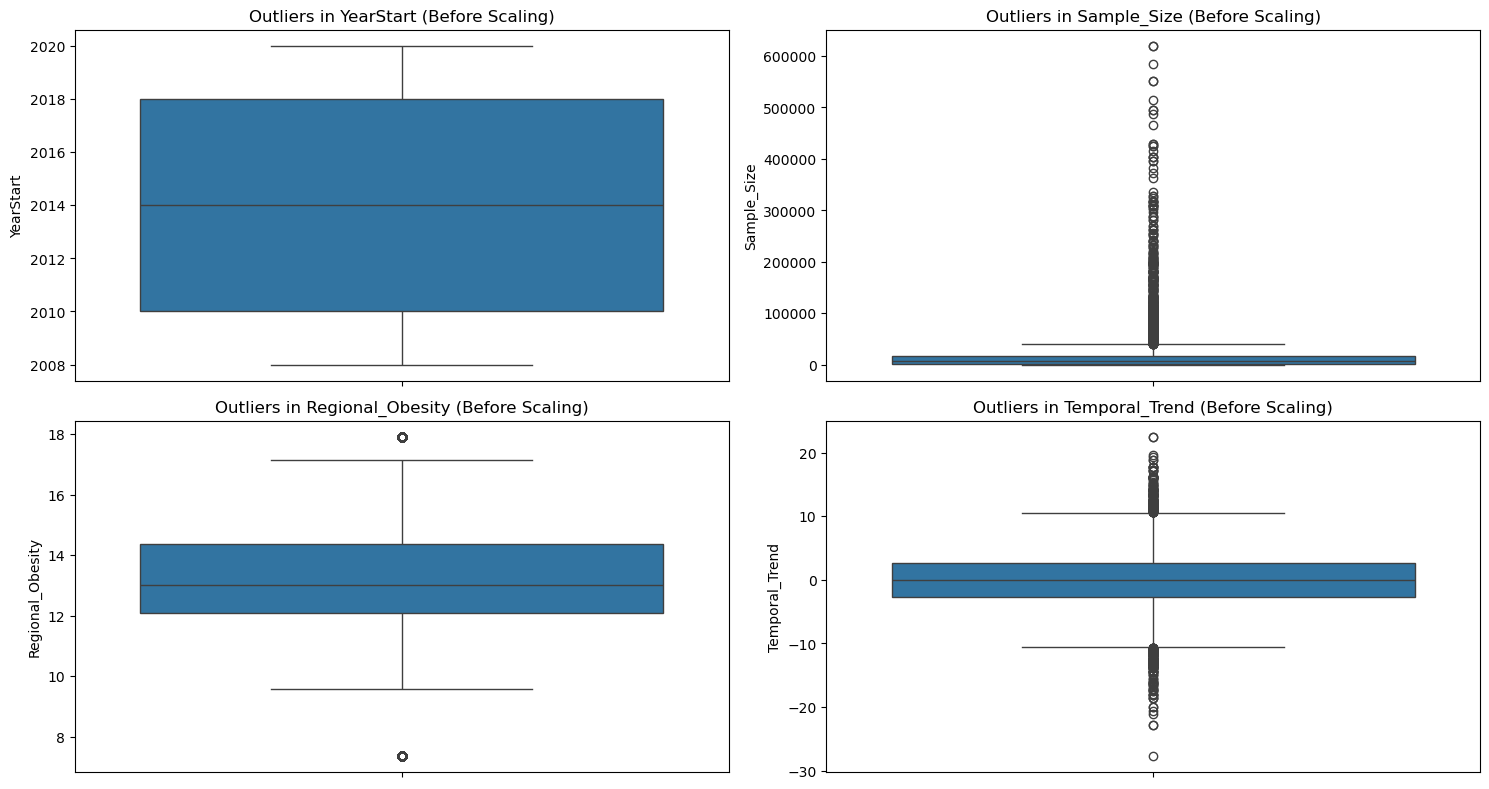


Skewness/Kurtosis Before Scaling:


,YearStart,Sample_Size,Regional_Obesity,Temporal_Trend
skew,-0.195900,7.412381,-0.230079,-0.037388
kurtosis,-1.296376,81.138530,1.028822,1.258363


In [24]:
# Select original numerical features (before polynomial/pd.get_dummies)
original_num_column = ['YearStart', 'Sample_Size', 'Regional_Obesity', 'Temporal_Trend']
num_data =df[original_num_column]

# Plot boxplots before scaling
plt.figure(figsize=(15, 8))
for i, col in enumerate(original_num_column,1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=num_data[col])
    plt.title(f'Outliers in {col} (Before Scaling)')
plt.tight_layout()
plt.show()

# Print skewness/kurtosis
print("\nSkewness/Kurtosis Before Scaling:")
display(num_data.agg(['skew','kurtosis']))


In [25]:
# Initialize and apply RobustScaler to ORIGINAL numerical features
scaler = RobustScaler()
df[original_num_column] = scaler.fit_transform(df[original_num_column])

# Verify scaling
print("\nSample Data After Scaling:")
display(df[original_num_column].head())


Sample Data After Scaling:


,YearStart,Sample_Size,Regional_Obesity,Temporal_Trend
4297,-0.75,-0.383799,0.592582,0.000000
4804,-0.75,0.254320,0.592582,0.471698
5280,-0.75,-0.380940,0.592582,-0.754717
6066,-0.75,0.813596,0.592582,-0.150943
6155,-0.75,-0.385197,0.592582,0.358491


In [26]:
poly = PolynomialFeatures(degree=2, include_bias=False)
poly_features = poly.fit_transform(df[original_num_column])
poly_feature_names = poly.get_feature_names_out(original_num_column)
X_poly = pd.DataFrame(poly_features, columns=poly_feature_names, index=df.index)

# Continue with your existing categorical processing...
X = pd.concat([df[['LocationDesc', 'Age(months)', 'Race/Ethnicity']], X_poly], axis=1)
X = pd.get_dummies(X, columns=['LocationDesc', 'Age(months)', 'Race/Ethnicity'], drop_first=True)

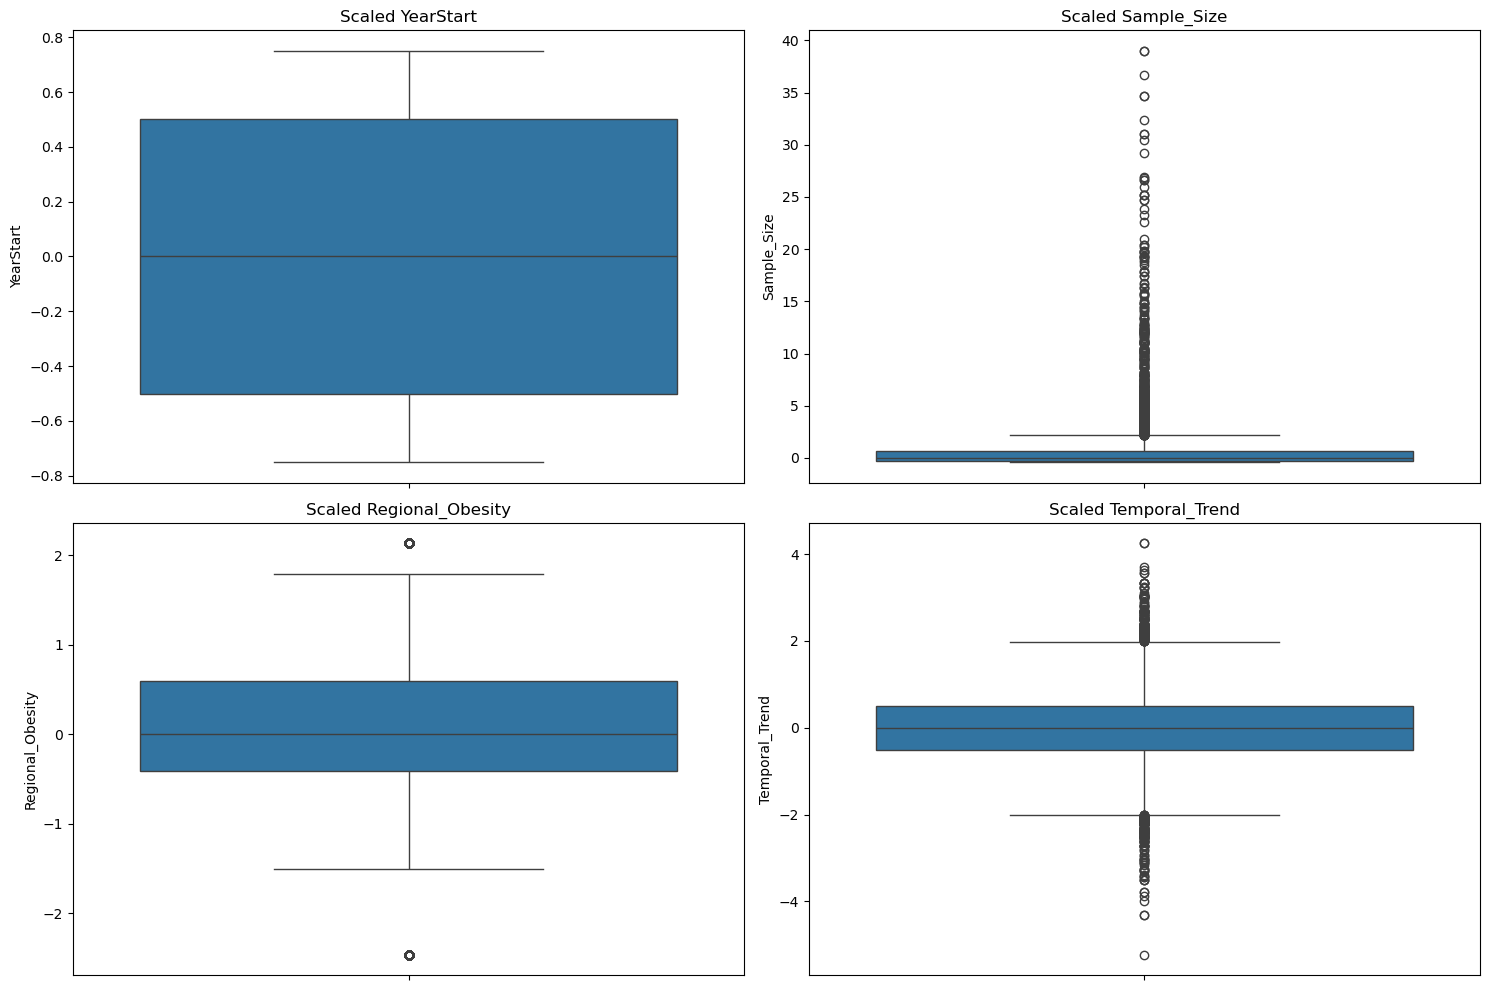


Skewness/Kurtosis After Full Processing:


,YearStart,Sample_Size,Regional_Obesity,Temporal_Trend,YearStart^2,YearStart Sample_Size,YearStart Regional_Obesity,YearStart Temporal_Trend,Sample_Size^2,Sample_Size Regional_Obesity,Sample_Size Temporal_Trend,Regional_Obesity^2,Regional_Obesity Temporal_Trend,Temporal_Trend^2
skew,-0.195900,7.412381,-0.230079,-0.037388,0.322734,-4.689092,-0.056482,-0.090854,20.008559,9.569396,10.844140,3.123323,-0.191285,4.848711
kurtosis,-1.296376,81.138530,1.028822,1.258363,-1.427289,106.586186,3.621899,3.737441,506.858400,129.256983,200.235422,10.239038,15.174221,41.728645


In [27]:
# Plot boxplots of scaled polynomial features

plt.figure(figsize=(15,10))
for i, col in enumerate(poly_feature_names[:4], 1):  
    plt.subplot(2, 2, i)
    sns.boxplot(y=X_poly[col])
    plt.title(f'Scaled {col}')
plt.tight_layout()
plt.show()

print("\nSkewness/Kurtosis After Full Processing:")
display(X_poly.agg(['skew', 'kurtosis']).head(4))

### 3. Exploratory Data Analysis (EDA)


Insight: Correlation matrix


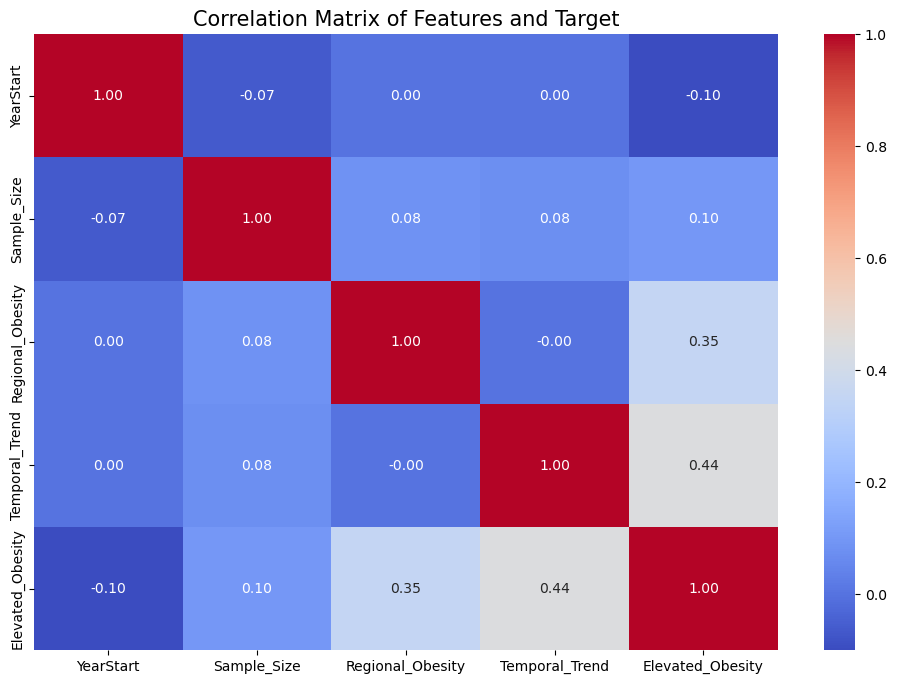

In [29]:
# Define features and target for correlation analysis
target = 'Elevated_Obesity'
correlation_features = ['YearStart','Sample_Size', 'Regional_Obesity','Temporal_Trend', target]

# Compute correlation matrix
corr_matrix = df[correlation_features].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix of Features and Target", size=15)
print("\nInsight: Correlation matrix")
plt.show()
plt.close()


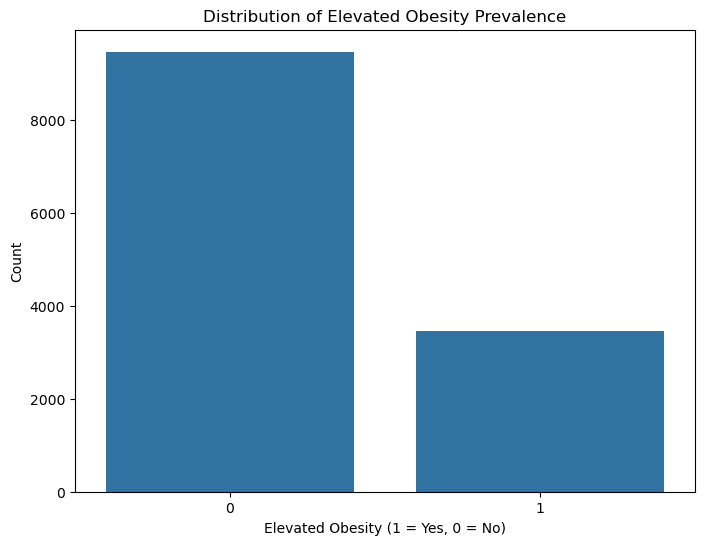

In [30]:
# Visualize distribution of Elevated_Obesity
plt.figure(figsize=(8,6))
sns.countplot(x='Elevated_Obesity', data=df)
plt.title('Distribution of Elevated Obesity Prevalence')
plt.xlabel("Elevated Obesity (1 = Yes, 0 = No)")
plt.ylabel('Count')
plt.show()

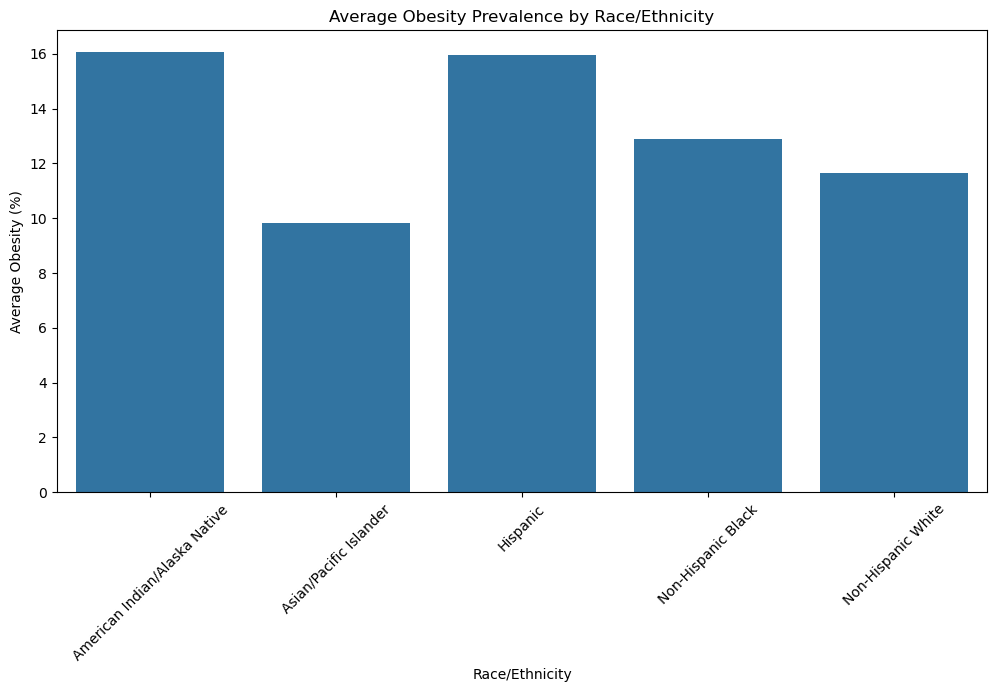

In [31]:
# Visualize obesity prevalence by Race/Ethnicity
df_mean = df.groupby('Race/Ethnicity', as_index=False)['Data_Value'].mean()

plt.figure(figsize=(12, 6))
sns.barplot( x='Race/Ethnicity',y='Data_Value',data=df_mean,errorbar=None)
plt.title('Average Obesity Prevalence by Race/Ethnicity')
plt.xticks(rotation=45)
plt.ylabel('Average Obesity (%)')
plt.show()

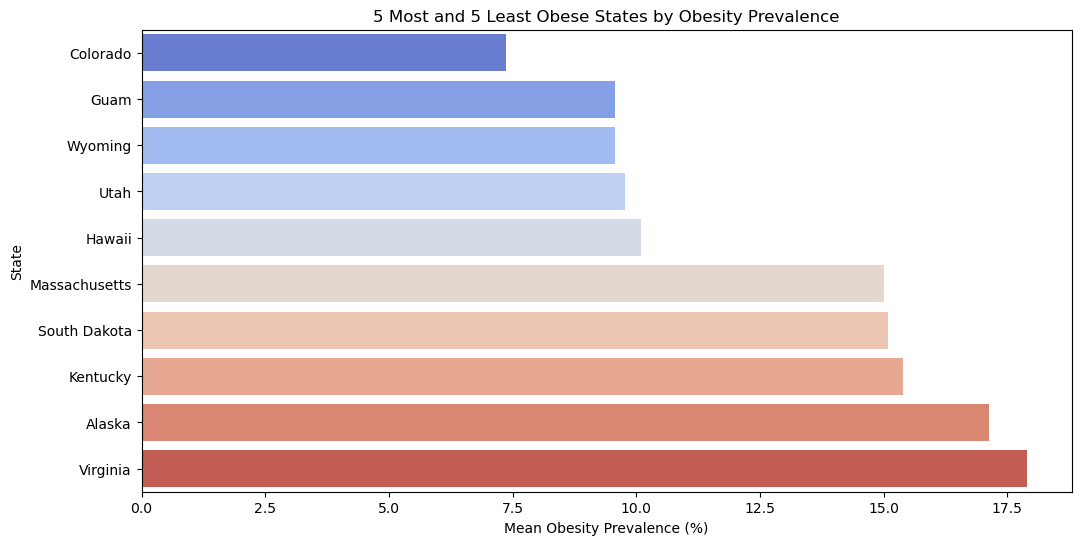

In [32]:
# Visualize 5 most and 5 least obese states by Obesity Prevalence
plt.figure(figsize=(12,6))

# Calculate mean obesity prevalence by state
state_obesity =df.groupby('LocationDesc')['Data_Value'].mean().sort_values()

# Select top 5 and bottom 5 states
top_5_states =state_obesity.tail(5)
bottom_5_states =state_obesity.head(5)

# Combine top and bottom states
combined_states = pd.concat([bottom_5_states, top_5_states])

# Create bar plot with hue to avoid Seaborn warning
sns.barplot(x=combined_states.values, y=combined_states.index, hue=combined_states.index, palette='coolwarm', legend=False)
plt.title('5 Most and 5 Least Obese States by Obesity Prevalence')
plt.xlabel('Mean Obesity Prevalence (%)')
plt.ylabel('State')
plt.show()


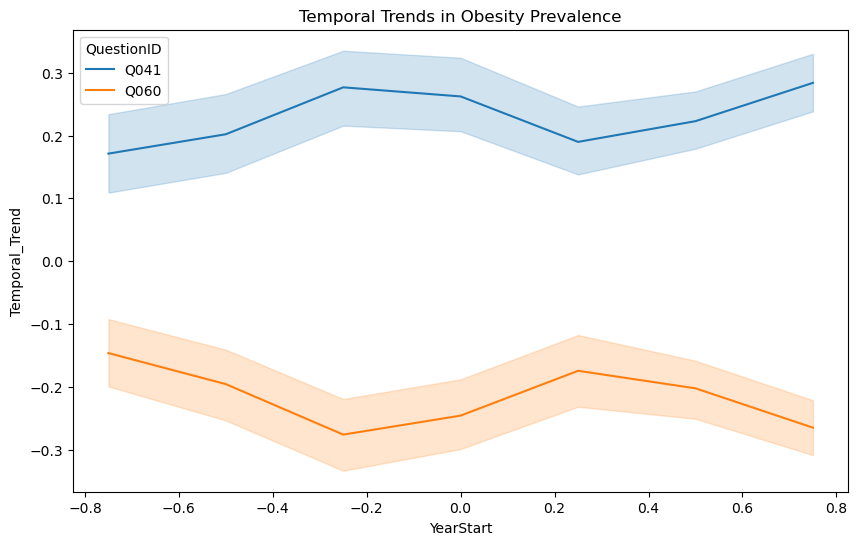

In [33]:
# Visualize temporal trends by QuestionID
plt.figure(figsize=(10,6))
sns.lineplot(x='YearStart', y='Temporal_Trend', hue='QuestionID', data=df)
plt.title('Temporal Trends in Obesity Prevalence')
plt.show()


#### Q041 - Percent of WIC children aged 2 to 4 years who have obesity
#### Q060 -  Percent of WIC children aged 3-23 months old who have a high weight-for-length


## 4 Model Selection and Training

In [36]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [37]:
# Logistic Regression with hyperparameter tuning
param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'saga'],
    'penalty': ['l1', 'l2']
}
lr_grid = GridSearchCV(LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
                       param_grid_lr, cv=5, scoring='f1', n_jobs=-1)
lr_grid.fit(X_train, y_train)

# Extract and predict with best Logistic Regression model
print("Best Logistic Regression Parameters - ", lr_grid.best_params_)
lr_best = lr_grid.best_estimator_
y_pred_lr = lr_best.predict(X_test)
y_pred_proba_lr = lr_best.predict_proba(X_test)[:, 1]

Best Logistic Regression Parameters -  {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}


In [38]:
# CatBoost Classifier with hyperparameter tuning
from tempfile import gettempdir

catboost_model = CatBoostClassifier(verbose=0, random_state=42)
param_grid_catboost = {
    'depth': [3, 5],
    'learning_rate': [0.01, 0.1],
    'iterations': [100, 200]
}
grid_search_catboost = GridSearchCV(catboost_model, param_grid_catboost, cv=5, scoring='f1', n_jobs=-1)
grid_search_catboost.fit(X_train, y_train)

# Extract and predict with best CatBoost model
print("Best CatBoost Parameters:", grid_search_catboost.best_params_)
catboost_best = grid_search_catboost.best_estimator_
y_pred_catboost = catboost_best.predict(X_test)
y_pred_proba_catboost = catboost_best.predict_proba(X_test)[:, 1]


C:\Users\Saran\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
15 fits failed out of a total of 40.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Saran\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\Saran\anaconda3\Lib\site-packages\catboost\core.py", line 5245, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, sample_weight, None, None, None, None, baseline, use_best_model,
  File "C:\Users\Saran\anaconda3\Lib\site-packages\catboost\core.py", line 

Best CatBoost Parameters: {'depth': 5, 'iterations': 200, 'learning_rate': 0.1}


## 5. Model Performance Evaluation

#### Model Performance Evaluation

###### Accuracy: Measures overall correctness of predictions
###### Precision: Evaluates the proportion of true positives among predicted positives
###### Recall (Sensitivity): Measures the proportion of actual positives correctly identified
###### F1-Score: Harmonic mean of precision and recall
###### ROC-AUC: Evaluates model's ability to distinguish between classes
#### Model Comparison

###### Logistic Regression vs. CatBoost Classifier performance comparison
###### ROC Curve visualization for both models

#### Visualizations
###### ROC Curves
###### Plotting True Positive Rate (TPR) vs. False Positive Rate (FPR)
###### AUC scores for model comparison


In [41]:
# Model Performance Evaluation
def evaluate_model(y_true, y_pred, y_pred_proba, model_name):
    print(f"\n{model_name} Performance:")
    print("Accuracy:",accuracy_score(y_true, y_pred))
    print("Precision:",precision_score(y_true, y_pred))
    print("Recall:",recall_score(y_true, y_pred))
    print("F1-Score:",f1_score(y_true, y_pred))
    print("ROC-AUC:",roc_auc_score(y_true, y_pred_proba))

# Evaluate Logistic Regression
evaluate_model(y_test, y_pred_lr, y_pred_proba_lr,"Logistic Regression")

# Evaluate CatBoost
evaluate_model(y_test, y_pred_catboost, y_pred_proba_catboost,"CatBoost")


Logistic Regression Performance:
Accuracy: 0.8336557059961315
Precision: 0.6406926406926406
Recall: 0.8579710144927536
F1-Score: 0.7335811648079306
ROC-AUC: 0.9276616572980001

CatBoost Performance:
Accuracy: 0.8986460348162476
Precision: 0.8627118644067797
Recall: 0.7376811594202899
F1-Score: 0.7953125
ROC-AUC: 0.9567978279989293


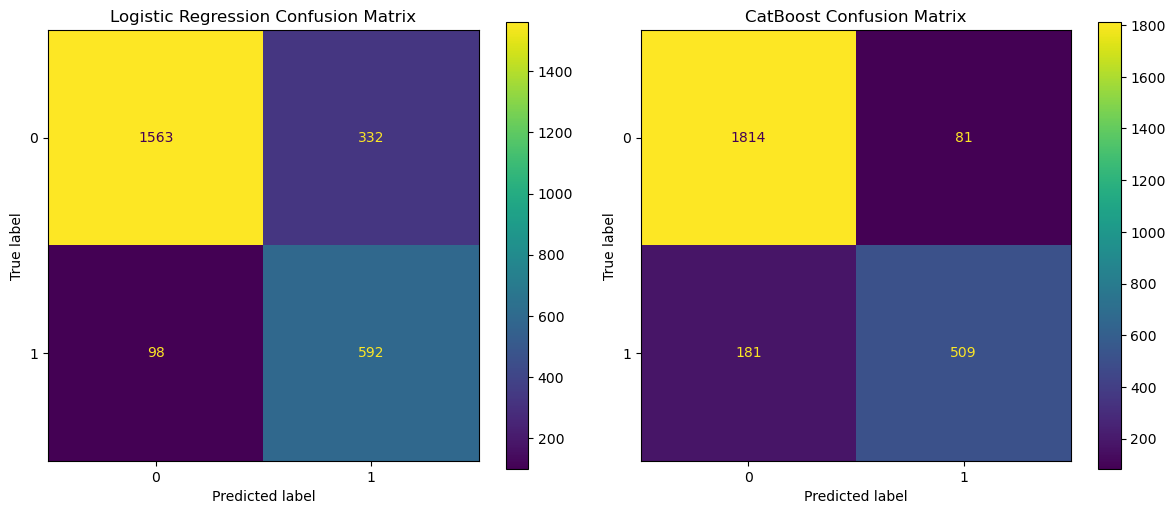

In [42]:
# Visualize confusion matrices
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
cm_lr =confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm_lr).plot(ax=plt.gca())
plt.title('Logistic Regression Confusion Matrix')

plt.subplot(1, 2, 2)
cm_catboost =confusion_matrix(y_test, y_pred_catboost)
ConfusionMatrixDisplay(cm_catboost).plot(ax=plt.gca())
plt.title('CatBoost Confusion Matrix')

plt.tight_layout()
plt.show()


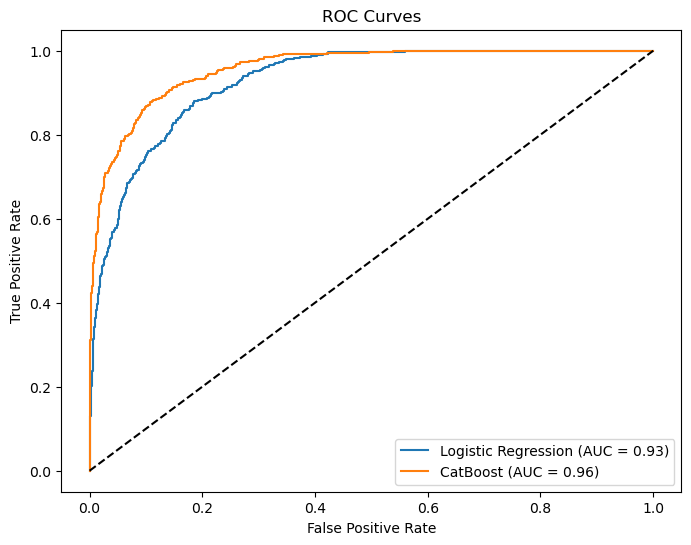

In [43]:
# Visualize ROC curves
plt.figure(figsize=(8, 6))
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_proba_lr):.2f})')
fpr_cb, tpr_cb, _ = roc_curve(y_test, y_pred_proba_catboost)
plt.plot(fpr_cb, tpr_cb, label=f'CatBoost (AUC = {roc_auc_score(y_test, y_pred_proba_catboost):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()


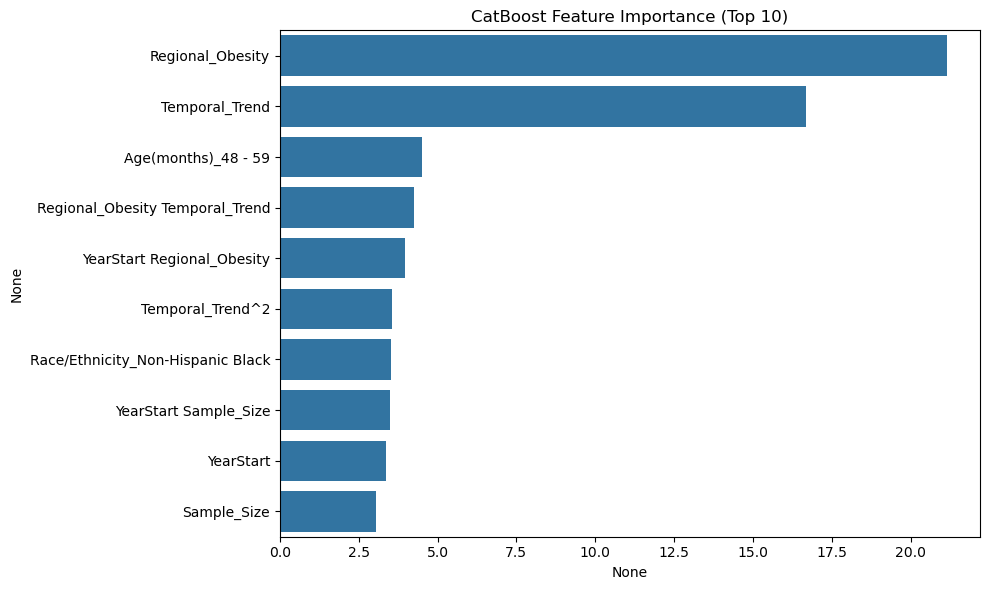

In [44]:
# Visualize CatBoost feature importance
plt.figure(figsize=(10, 6))
feature_importance =pd.Series(catboost_best.feature_importances_,index=X.columns).sort_values(ascending=False)[:10]
sns.barplot(x=feature_importance,y=feature_importance.index)
plt.title('CatBoost Feature Importance (Top 10)')
plt.tight_layout()

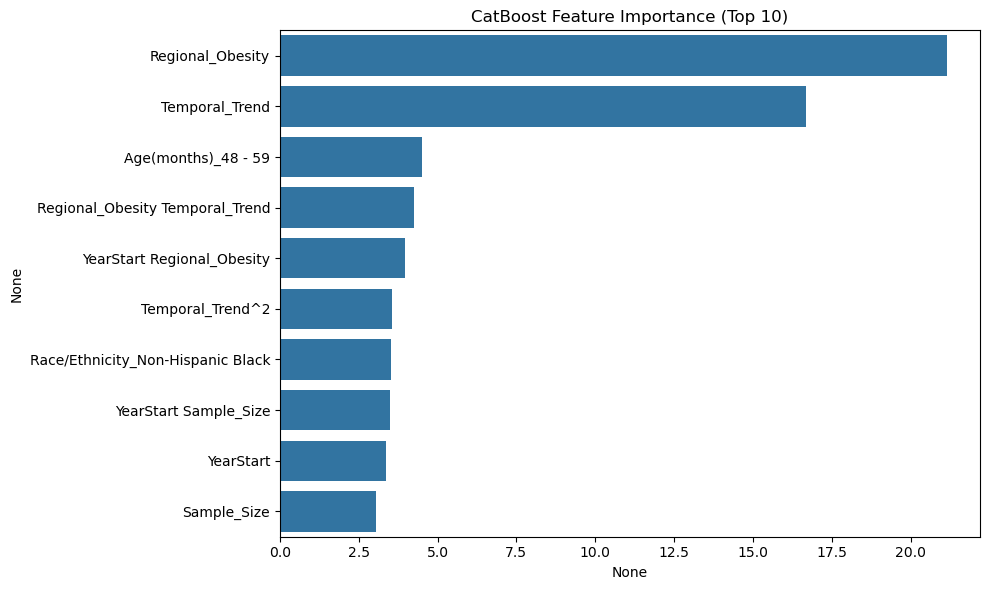

In [45]:
# Visualize CatBoost feature importance
plt.figure(figsize=(10, 6))
feature_importance = pd.Series(catboost_best.feature_importances_, index=X.columns).sort_values(ascending=False)[:10]
sns.barplot(x=feature_importance, y=feature_importance.index)
plt.title('CatBoost Feature Importance (Top 10)')
plt.tight_layout()